# Film Yorumlarında Duygu Analizi (Bag of Words Meets Bags of Popcorn)

IMDB sitesindeki film yorumları verilmiş. Her yorum için yazarın filmi beğenip beğenmediği (olumlu = 1, olumsuz = 0) biliniyor. Bizden istenen: etiketsiz test yorumlarının olumlu olma olasılığını tahmin etmek.

Bilgisayar metni doğrudan anlayamaz, sayıya çevirmemiz gerekir. Bu notebook'ta metni önce **Bag of Words** (kelime sayıları), sonra **TF-IDF** (kelimelerin önem ağırlığı) ile sayıya çevirip farklı modelleri karşılaştıracağız.

In [1]:
import pandas as pd
import numpy as np
import re
import pickle
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, accuracy_score

In [2]:
train = pd.read_csv('labeledTrainData.tsv', sep='\t')
test = pd.read_csv('testData.tsv', sep='\t')
sample = pd.read_csv('sampleSubmission.csv')

print('train:', train.shape, '| test:', test.shape)
train.head()

train: (25000, 3) | test: (25000, 2)


,id,sentiment,review
0,5814_8,1,With all this stuff going down at the moment w...
1,2381_9,1,"\The Classic War of the Worlds\"" by Timothy Hi..."
2,7759_3,0,The film starts with a manager (Nicholas Bell)...
3,3630_4,0,It must be assumed that those who praised this...
4,9495_8,1,Superbly trashy and wondrously unpretentious 8...


In [3]:
def temizle(metin):
    return re.sub('<.*?>', ' ', metin) 

train['temiz'] = train.review.apply(temizle)
test['temiz'] = test.review.apply(temizle)

ornek = train[train.review.str.contains('<br />')].iloc[0]
yer = ornek.review.find('<br />')
print('ÖNCE :', ornek.review[max(0, yer - 80):yer + 80])
print()
print('SONRA:', ornek.temiz[max(0, yer - 80):yer + 80])

ÖNCE : s feeling towards the press and also the obvious message of drugs are bad m'kay.<br /><br />Visually impressive but of course this is all about Michael Jackson 

SONRA: s feeling towards the press and also the obvious message of drugs are bad m'kay.  Visually impressive but of course this is all about Michael Jackson so unless 


In [4]:
print('Sınıf dağılımı:')
print(train.sentiment.value_counts())

train['kelime_sayisi'] = train.temiz.str.split().str.len()
print()
print('Yorum uzunluğu (kelime):')
print(train.kelime_sayisi.describe().round(0))

Sınıf dağılımı:
sentiment
1    12500
0    12500
Name: count, dtype: int64

Yorum uzunluğu (kelime):
count    25000.0
mean       231.0
std        172.0
min         10.0
25%        126.0
50%        173.0
75%        281.0
max       2460.0
Name: kelime_sayisi, dtype: float64


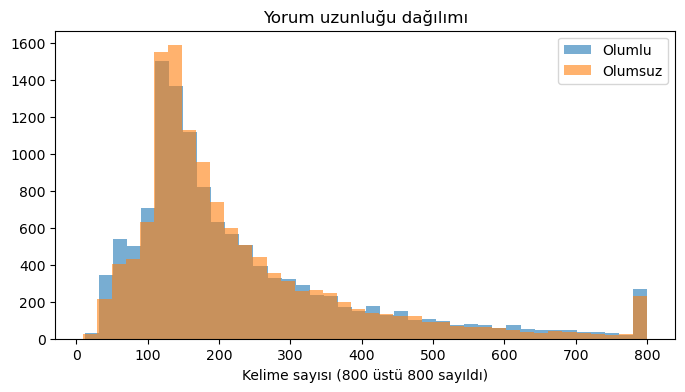

In [5]:
plt.figure(figsize=(8, 4))
plt.hist(train[train.sentiment == 1].kelime_sayisi.clip(upper=800), bins=40, alpha=0.6, label='Olumlu')
plt.hist(train[train.sentiment == 0].kelime_sayisi.clip(upper=800), bins=40, alpha=0.6, label='Olumsuz')
plt.xlabel('Kelime sayısı (800 üstü 800 sayıldı)')
plt.legend()
plt.title('Yorum uzunluğu dağılımı')
plt.show()

İki sınıfın uzunluk dağılımı birbirine çok benziyor, yani yorum uzunluğu duyguyu ayırt etmeye yaramaz. Asıl bilgi hangi kelimelerin kullanıldığında.

In [21]:
for etiket, ad in [(1, 'OLUMLU'), (0, 'OLUMSUZ')]:
    cv = CountVectorizer(stop_words='english', max_features=12)
    cv.fit(train[train.sentiment == etiket].temiz)
    print(ad, ':', list(cv.get_feature_names_out()))

OLUMLU : ['best', 'film', 'good', 'great', 'just', 'like', 'love', 'movie', 'people', 'really', 'story', 'time']
OLUMSUZ : ['bad', 'don', 'film', 'good', 'just', 'like', 'make', 'movie', 'people', 'really', 'story', 'time']


In [7]:
egitim, dogrulama = train_test_split(train, test_size=0.2, stratify=train.sentiment, random_state=42)
print('eğitim:', egitim.shape, '| doğrulama:', dogrulama.shape)

kelime_deseni = r"(?u)\b[\w']+\b"  
sonuclar = {}

def dene(isim, vektorlestirici, model):
    pipe = Pipeline([('vec', vektorlestirici), ('model', model)])
    pipe.fit(egitim.temiz, egitim.sentiment)
    if hasattr(pipe, 'predict_proba'):
        skor = pipe.predict_proba(dogrulama.temiz)[:, 1]
    else:
        skor = pipe.decision_function(dogrulama.temiz)
    sonuclar[isim] = {'AUC': roc_auc_score(dogrulama.sentiment, skor),
                      'Accuracy': accuracy_score(dogrulama.sentiment, pipe.predict(dogrulama.temiz))}
    print(isim, '->', {k: round(v, 4) for k, v in sonuclar[isim].items()})

eğitim: (20000, 5) | doğrulama: (5000, 5)


In [8]:
dene('Bag of Words + Logistic Regression',
     CountVectorizer(min_df=2, token_pattern=kelime_deseni),
     LogisticRegression(max_iter=2000))

Bag of Words + Logistic Regression -> {'AUC': 0.9457, 'Accuracy': 0.8822}


In [9]:
dene('TF-IDF + Logistic Regression',
     TfidfVectorizer(min_df=2, sublinear_tf=True, token_pattern=kelime_deseni),
     LogisticRegression(C=10, max_iter=1000))

TF-IDF + Logistic Regression -> {'AUC': 0.9619, 'Accuracy': 0.897}


In [10]:
dene('TF-IDF 1-2 gram + Naive Bayes',
     TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=kelime_deseni),
     MultinomialNB(alpha=0.1))

TF-IDF 1-2 gram + Naive Bayes -> {'AUC': 0.9545, 'Accuracy': 0.8878}


In [11]:
dene('TF-IDF 1-2 gram + Logistic Regression',
     TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=kelime_deseni),
     LogisticRegression(C=10, max_iter=1000))

TF-IDF 1-2 gram + Logistic Regression -> {'AUC': 0.9696, 'Accuracy': 0.9036}


In [12]:
dene('TF-IDF 1-2 gram + Linear SVM',
     TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=kelime_deseni),
     LinearSVC(C=0.5))

TF-IDF 1-2 gram + Linear SVM -> {'AUC': 0.9705, 'Accuracy': 0.9076}


                                          AUC  Accuracy
TF-IDF 1-2 gram + Linear SVM           0.9705    0.9076
TF-IDF 1-2 gram + Logistic Regression  0.9696    0.9036
TF-IDF + Logistic Regression           0.9619    0.8970
TF-IDF 1-2 gram + Naive Bayes          0.9545    0.8878
Bag of Words + Logistic Regression     0.9457    0.8822


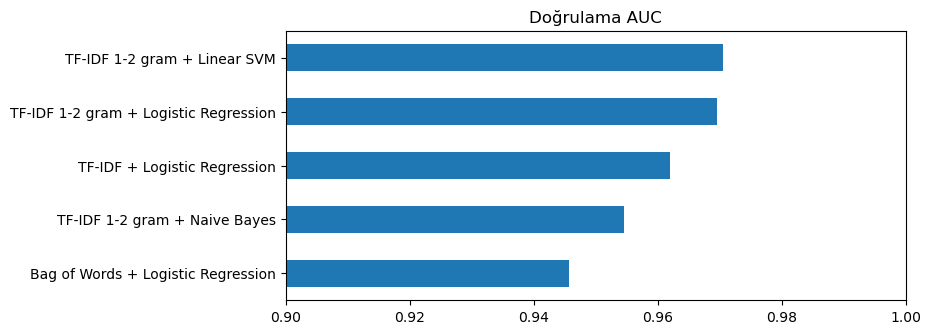

In [13]:
tablo = pd.DataFrame(sonuclar).T.sort_values('AUC', ascending=False).round(4)
print(tablo)
tablo.AUC.sort_values().plot(kind='barh', figsize=(8, 3.5), xlim=(0.9, 1.0))
plt.title('Doğrulama AUC')
plt.show()

In [14]:
model = Pipeline([
    ('vec', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=kelime_deseni)),
    ('model', LogisticRegression(C=10, max_iter=1000))
])
model.fit(train.temiz, train.sentiment)
print('Özellik sayısı:', len(model.named_steps['vec'].vocabulary_))

Özellik sayısı: 436937


In [15]:
kelimeler = model.named_steps['vec'].get_feature_names_out()
katsayi = model.named_steps['model'].coef_[0]
sirali = np.argsort(katsayi)
print('En OLUMSUZ:', list(kelimeler[sirali[:12]]))
print('En OLUMLU :', list(kelimeler[sirali[-12:]]))

En OLUMSUZ: ['worst', 'bad', 'awful', 'the worst', 'boring', 'waste', 'poor', 'terrible', 'dull', 'worse', 'poorly', 'nothing']
En OLUMLU : ['superb', 'today', 'fun', 'best', 'the best', '8', 'amazing', 'wonderful', '7', 'perfect', 'excellent', 'great']


In [16]:
test['sentiment'] = model.predict_proba(test.temiz)[:, 1]
sonuc = test[['id', 'sentiment']]
sonuc.to_csv('sonuc1.csv', index=False)
print(sonuc.shape)
sonuc.head()

(25000, 2)


,id,sentiment
0,12311_10,0.991353
1,8348_2,0.015769
2,5828_4,0.821349
3,7186_2,0.618879
4,12128_7,0.929516


In [17]:
print('id\'ler sample ile aynı mı:', (sonuc.id.values == sample.id.values).all())
print('boş değer var mı         :', sonuc.sentiment.isna().any())
print('olasılık aralığı         :', round(sonuc.sentiment.min(), 4), '-', round(sonuc.sentiment.max(), 4))
print('olumlu tahmin oranı (>0.5):', round((sonuc.sentiment > 0.5).mean(), 3))

id'ler sample ile aynı mı: True
boş değer var mı         : False
olasılık aralığı         : 0.0 - 1.0
olumlu tahmin oranı (>0.5): 0.5


In [18]:
denemeler = ['This movie was absolutely wonderful, I loved every minute of it!',
             'What a waste of time. The plot was boring and the acting was terrible.',
             'It was not good at all.']
for c in denemeler:
    print(round(model.predict_proba([c])[0][1], 3), '|', c)

0.984 | This movie was absolutely wonderful, I loved every minute of it!
0.0 | What a waste of time. The plot was boring and the acting was terrible.
0.048 | It was not good at all.


In [19]:
with open('model.pkl', 'wb') as f:
    pickle.dump(model, f)
print('model.pkl kaydedildi')

model.pkl kaydedildi


- Metni sayıya çevirmenin üç basamağını denedik: kelime sayıları (Bag of Words) → TF-IDF → TF-IDF + ikili kelime grupları. Her basamakta doğrulama AUC'si yükseldi.
- **Doğrulama AUC / Accuracy:** Bag of Words 0.946 / 0.884 → TF-IDF 0.962 / 0.897 → **TF-IDF 1-2 gram + Logistic Regression 0.970 / 0.904**. İkili kelime grupları (`not good`, `the worst` gibi) kelimenin bağlamını yakalayabildiği için fark yarattı.
- Naive Bayes hızlı ama bu veride Logistic Regression'dan geride kaldı. Linear SVM Logistic Regression ile aynı seviyede çıktı; yarışma olasılık istediği için Logistic Regression'ı seçtik.